# 2. Radial numbering: streets relative to a center point

Once every edge has a `street_id` (see
[`01_street_identity.ipynb`](01_street_identity.ipynb)), an address
scheme needs to know which way the numbers go, and how far along a
point is. Many towns grow outward from a center. Numbering climbs as
you move away from it. This is radial numbering.

`assign_street_directionality(..., numbering_mode="radial")`
implements this. Given a center point, `origin`, it classifies each
street as radial (runs toward or away from `origin`) or transversal
(runs around it, like a ring road). It picks a numbering start, then
walks the street recording each edge's position
(`street_start_length_m`, `street_end_length_m`, in meters).

In [1]:
import matplotlib.pyplot as plt
from _tutorial_utils import (
    build_idealized_grid, label_and_direct_radial, make_graph, plot_radial_directionality,
)

plt.rcParams["figure.dpi"] = 110

## Example 1: a radial street

A straight street running away from the origin, built as two segments.
Its two endpoints differ in distance from the origin by the street's
entire length. That's a 100% ratio, far above the 10%
`transversal_road_pct` default. So it's radial.

Numbering starts at the end nearest the origin: that's where the
labeled length range starts at 0m, growing outward.

,street_id,road_type,length_m
0,1,radial,50.0


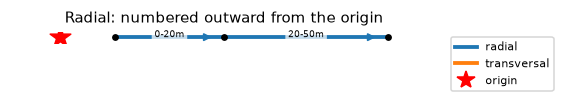

In [2]:
G = make_graph([
    (0, 1, (10, 0), (30, 0)),
    (1, 2, (30, 0), (60, 0)),
])
nodes_gdf, edges_gdf, streets_df = label_and_direct_radial(G, origin=(0, 0))
display(streets_df[["street_id", "road_type", "length_m"]])
plot_radial_directionality(edges_gdf, nodes_gdf, streets_df, origin=(0, 0),
                            title="Radial: numbered outward from the origin")
plt.show()

## Example 2: a transversal street

A street connecting a point due north of the origin to a point due
east of it. Both endpoints are the same distance from the origin. A
0% ratio, well below the threshold. So it's transversal.

Numbering runs clockwise. It starts at the north point, since sweeping
clockwise from north reaches east next.

,street_id,road_type,length_m
0,1,transversal,14.142136


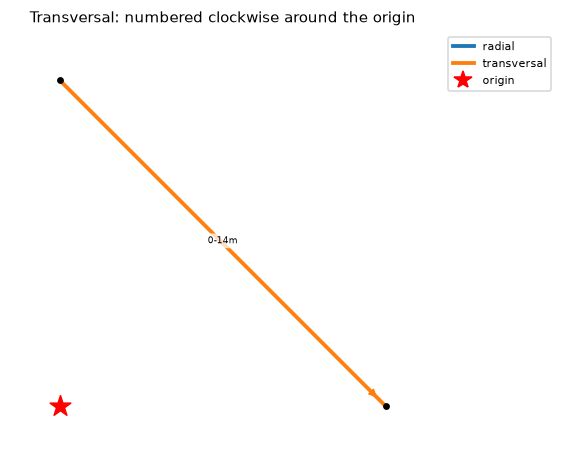

In [3]:
G = make_graph([
    (0, 1, (0, 10), (10, 0)),  # node 0 = north of origin, node 1 = east of origin
])
nodes_gdf, edges_gdf, streets_df = label_and_direct_radial(G, origin=(0, 0))
display(streets_df[["street_id", "road_type", "length_m"]])
plot_radial_directionality(edges_gdf, nodes_gdf, streets_df, origin=(0, 0),
                            title="Transversal: numbered clockwise around the origin")
plt.show()

## Example 3: a closed loop (ring road)

A 24-sided polygon approximating a circle around the origin. Each turn
is only 15°, under the 20° merge threshold. The whole ring collapses
to a single `street_id` with no natural start or end.

For a loop, the function falls back to the two most-distant nodes as
an approximation. It numbers outward from one of them in both
directions at once. The cumulative length only reaches about half the
ring's circumference before the two directions meet at the opposite
seam.

,street_id,road_type,length_m
0,1,transversal,626.525723


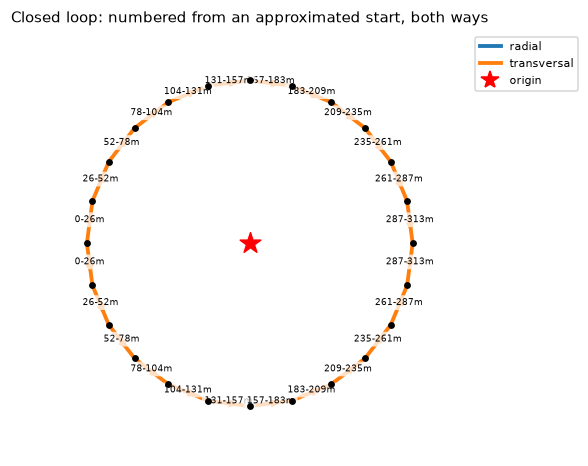

In [4]:
import math

n, radius = 24, 100.0
loop_edges = []
for i in range(n):
    a0, a1 = 2 * math.pi * i / n, 2 * math.pi * (i + 1) / n
    p0 = (radius * math.cos(a0), radius * math.sin(a0))
    p1 = (radius * math.cos(a1), radius * math.sin(a1))
    loop_edges.append((i, (i + 1) % n, p0, p1))

G = make_graph(loop_edges)
nodes_gdf, edges_gdf, streets_df = label_and_direct_radial(G, origin=(0, 0))
display(streets_df[["street_id", "road_type", "length_m"]])
plot_radial_directionality(edges_gdf, nodes_gdf, streets_df, origin=(0, 0),
                            title="Closed loop: numbered from an approximated start, both ways")
plt.show()

## Putting it together: the idealized grid

Reusing the idealized grid builder (all residential, no named or
primary rows), with the origin at `(200, 50)`. Horizontally centered
on the grid, but near one edge vertically.

Every row spans the same x-range around the origin's x. Both endpoints
are equidistant from the origin. All rows come out transversal. Every
column spans the same y-range, but the origin's y sits near one end.
All columns come out radial, numbered outward from the end nearest the
origin.

A perfectly centered origin would make every row and column
transversal, by the same symmetry. This origin is off-center on
purpose, to show the radial case too.

,street_id,road_type,length_m
0,1,transversal,400.0
1,2,radial,400.0
2,3,radial,400.0
3,4,radial,400.0
4,5,radial,400.0
5,6,radial,400.0
6,7,transversal,400.0
7,8,transversal,400.0
8,9,transversal,400.0
9,10,transversal,400.0


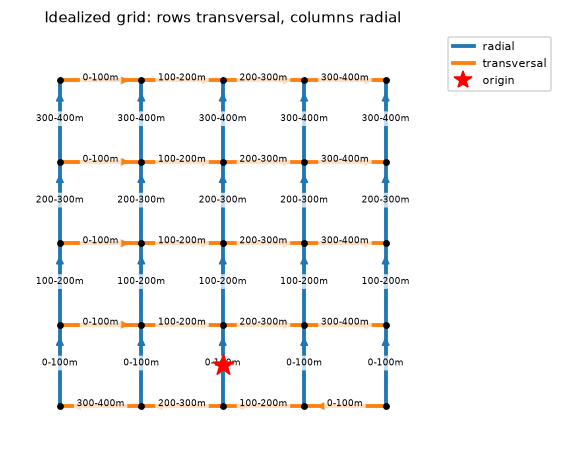

In [5]:
ROWS, COLS, SPACING = 5, 5, 100.0
G = build_idealized_grid(rows=ROWS, cols=COLS, spacing=SPACING, named_row=None, primary_row=None)
origin = (200.0, 50.0)

nodes_gdf, edges_gdf, streets_df = label_and_direct_radial(G, origin=origin, transversal_road_pct=10.0)
display(streets_df[["street_id", "road_type", "length_m"]])
plot_radial_directionality(edges_gdf, nodes_gdf, streets_df, origin=origin,
                            title="Idealized grid: rows transversal, columns radial")
plt.show()

The labeled ranges show cumulative length increasing outward for
radial streets, clockwise for transversal ones. These are exactly the
`street_start_length_m`/`street_end_length_m` fields
`assign_street_directionality` adds to `edges_gdf`.

Next: [`03_grid_numbering.ipynb`](03_grid_numbering.ipynb) covers the
alternative grid mode, for towns with no single meaningful center
point.